In [8]:
#nstall libraries
%pip install librosa
%pip install torch==2.8.0 torchaudio==2.8.0 --index-url https://download.pytorch.org/whl/cpu
%pip install coqui-tts


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
#Import libraries
import librosa
from IPython.display import display, Audio
import torch
from TTS.api import TTS

In [2]:
#Load and play audio files
audio1, sr1=librosa.load('audio/Jane_doe_voice/Short recording.wav', sr=None)
display(Audio(audio1,rate=sr1))

audio2, sr2=librosa.load('audio/Jane_doe_voice/Medium recording.wav', sr=None)
display(Audio(audio2,rate=sr2))

audio3, sr3=librosa.load('audio/Jane_doe_voice/Long recording.wav', sr=None)
display(Audio(audio3,rate=sr3))

C:\Users\sydne\PycharmProjects\DataWranglingClass\CSC425-AI-Project\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


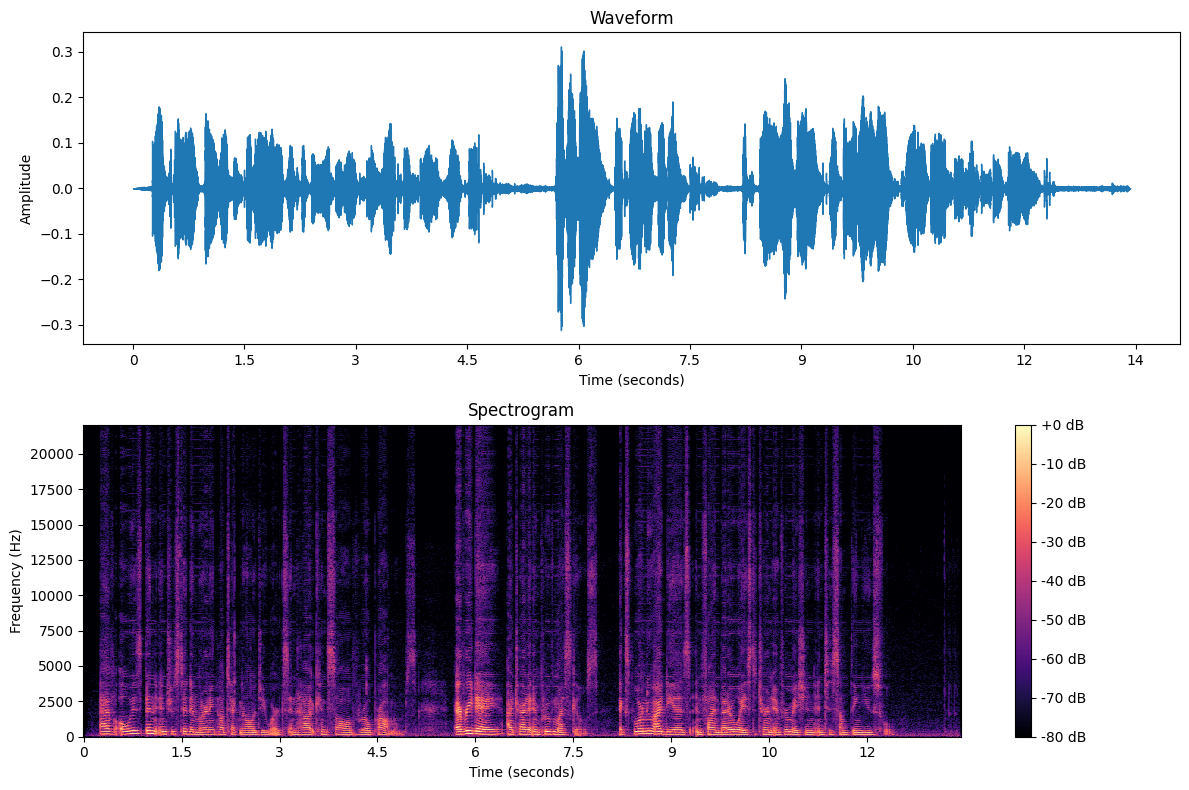

In [26]:
#audio preprocessing - choose audio to view in waveform and spectrogram, this choice will carry over to the other preprocessing steps.

# Import libraries
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# List of audio files
audio_files = {
    "long": "audio/Jane_doe_voice/Long recording.wav",
    "medium": "audio/Jane_doe_voice/Medium recording.wav",
    "short": "audio/Jane_doe_voice/Short recording.wav"
}


audio_choice = input("Select an audio file (long, medium, or short): ")

if audio_choice in audio_files:
    file = audio_files[audio_choice]

    # Load the selected audio file
    y, sr = librosa.load(file, sr=None)

    # Create waveform and spectrogram plots
    plt.figure(figsize=(12, 8))

    # Waveform
    plt.subplot(2, 1, 1)
    librosa.display.waveshow(y, sr=sr)
    plt.title("Waveform")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")

    # Spectrogram
    D = librosa.stft(y)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    plt.subplot(2, 1, 2)
    librosa.display.specshow(
        S_db,
        sr=sr,
        x_axis="time",
        y_axis="hz"
    )
    plt.colorbar(format="%+2.0f dB")
    plt.title("Spectrogram")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Frequency (Hz)")

    plt.tight_layout()
    plt.show()

else:
    print("Invalid choice! Please select long, medium, or short.")



In [27]:
# audio preprocessing - trim leading/trailing silence

choice = input("Do you want to trim leading and trailing silence? (y/n): ")

if choice.lower() == "y":
    y_trimmed, _ = librosa.effects.trim(y, top_db=20)

    plt.figure(figsize=(10, 5))
    librosa.display.waveshow(y_trimmed, sr=sr)
    plt.title("Trimmed Audio Waveform")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.show()

    print("Silence trimming complete!")

else:
    y_trimmed = y
    print("Skipping silence trimming.")

Skipping silence trimming.


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


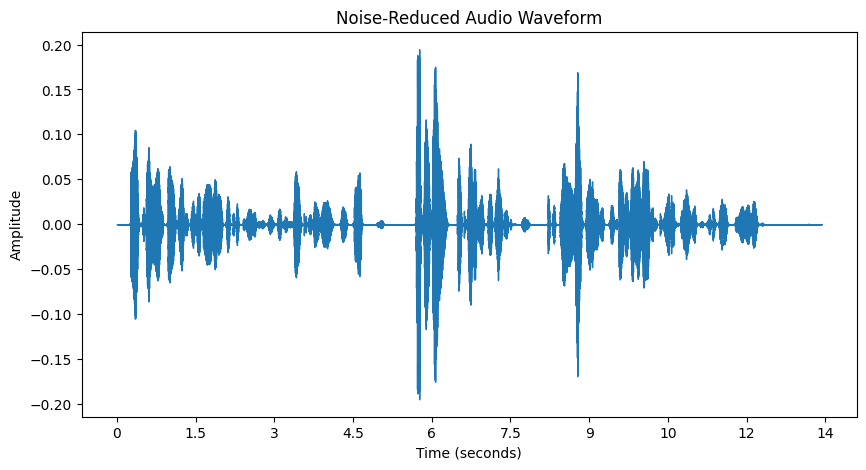

Noise reduction complete!


In [28]:
#preprosessing - reduce background noise
%pip install noisereduce

import noisereduce as nr

choice = input("Do you want to reduce background noise? (y/n): ")

if choice.lower() == "y":
    y_denoised = nr.reduce_noise(y=y_trimmed, sr=sr)

    plt.figure(figsize=(10, 5))
    librosa.display.waveshow(y_denoised, sr=sr)
    plt.title("Noise-Reduced Audio Waveform")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.show()

    print("Noise reduction complete!")

else:
    y_denoised = y_trimmed
    print("Skipping noise reduction.")

In [29]:
# audio preprocessing - normalize loudness

%pip install pyloudnorm

import pyloudnorm as pyln

choice = input("Do you want to normalize loudness? (y/n): ")

if choice.lower() == "y":
    # Measure the audio loudness
    meter = pyln.Meter(sr)
    loudness = meter.integrated_loudness(y_denoised)

    # Normalize the audio loudness to -23 LUFS
    y_normalized = pyln.normalize.loudness(
        y_denoised,
        loudness,
        -23.0
    )

    # Plot the normalized audio
    plt.figure(figsize=(10, 5))
    librosa.display.waveshow(y_normalized, sr=sr)
    plt.title("Loudness-Normalized Audio Waveform")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Amplitude")
    plt.show()

    print("Loudness normalization complete!")

else:
    y_normalized = y_denoised
    print("Skipping loudness normalization.")


Note: you may need to restart the kernel to use updated packages.Requirement already satisfied: pyloudnorm in c:\users\sydne\pycharmprojects\datawranglingclass\csc425-ai-project\.venv\lib\site-packages (0.2.0)




[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Skipping loudness normalization.


In [30]:
# Save the processed audio, whether preprocessing was applied or skipped

import os
import soundfile as sf

os.makedirs("audio/Processed", exist_ok=True)

if audio_choice == "short":
    output_file = "audio/Processed/JD_short.wav"
elif audio_choice == "medium":
    output_file = "audio/Processed/JD_medium.wav"
elif audio_choice == "long":
    output_file = "audio/Processed/JD_long.wav"

sf.write(output_file, y_normalized, sr)

print("Audio saved to:", output_file)

Audio saved to: audio/Processed/JD_long.wav


In [31]:
#Initialize the xtts-v2 model
model_name='tts_models/multilingual/multi-dataset/xtts_v2'
model=TTS(model_name).to('cpu')

#Generate an output audio files that read a text in the same voice as the input file
model.tts_to_file(
    text='This is a prototype to test if my program is working. Wish us luck!',
    file_path='audio/Replicated/JD_short.wav',
    speaker_wav='audio/Processed/JD_short.wav',
    language='en'
)

model.tts_to_file(
    text='This is a prototype to test if my program is working. Wish us luck!',
    file_path='audio/Replicated/JD_Medium.wav',
    speaker_wav='audio/Processed/JD_medium.wav',
    language='en'
)

model.tts_to_file(
    text='This is a prototype to test if my program is working. Wish us luck!',
    file_path='audio/Replicated/JD_Long.wav',
    speaker_wav='audio/Processed/JD_long.wav',
    language='en'
)


Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 186.94it/s]
C:\Users\sydne\PycharmProjects\DataWranglingClass\CSC425-AI-Project\.venv\lib\site-packages\torchaudio\_backend\utils.py:213: UserWarning: In 2.9, this function's implementation will be changed to use torchaudio.load_with_torchcodec` under the hood. Some parameters like ``normalize``, ``format``, ``buffer_size``, and ``backend`` will be ignored. We recommend that you port your code to rely directly on TorchCodec's decoder instead: https://docs.pytorch.org/torchcodec/stable/generated/torchcodec.decoders.AudioDecoder.html#torchcodec.decoders.AudioDecoder.
  warnings.warn(


'audio/Replicated/JD_Long.wav'

In [32]:
#Load and play the generated audio file
output1,sr=librosa.load('audio/Replicated/JD_short.wav', sr=None)
display(Audio(output1,rate=sr))

output2,sr=librosa.load('audio/Replicated/JD_Medium.wav', sr=None)
display(Audio(output2,rate=sr))

output3,sr=librosa.load('audio/Replicated/JD_Long.wav', sr=None)
display(Audio(output3,rate=sr))